# M49 — Cross-Dataset Testing

## AuthentiScore

This notebook evaluates the AuthentiScore Random Forest model on an external
Cresci-2017-derived Twitter user dataset.

External dataset:
- genuine_users.csv
- spam_user.csv

Objective:
Evaluate how well the AuthentiScore feature-based model generalizes to an
external dataset that was not used during the original model training.

Metrics:
- Accuracy
- Precision
- Recall
- F1 Score
- ROC-AUC
- Confusion Matrix

In [1]:
import os
import sys
import joblib
import numpy as np
import pandas as pd

from pathlib import Path

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

import matplotlib.pyplot as plt

In [2]:
from pathlib import Path

CURRENT_DIR = Path.cwd()

print("Current directory:")
print(CURRENT_DIR)

# Try to locate AuthentiScore project root
possible_roots = [
    CURRENT_DIR,
    CURRENT_DIR.parent,
    CURRENT_DIR.parent.parent
]

PROJECT_ROOT = None

for root in possible_roots:
    if (root / "data").exists() and (root / "backend").exists():
        PROJECT_ROOT = root
        break

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Could not locate the AuthentiScore project root. "
        "Please open this notebook from the AuthentiScore project."
    )

print("\nProject root:")
print(PROJECT_ROOT)

Current directory:
c:\Users\Acer\Documents\AuthentiScore\notebooks

Project root:
c:\Users\Acer\Documents\AuthentiScore


In [5]:
EXTERNAL_DIR = PROJECT_ROOT / "data" / "external" / "cresci2017"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
MODEL_DIR = PROJECT_ROOT / "backend" / "trained_models"

PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

GENUINE_PATH = EXTERNAL_DIR / "genuine_users.csv"
SPAM_PATH = EXTERNAL_DIR / "spam_user.csv"

print("External dataset directory:")
print(EXTERNAL_DIR)

print("\nGenuine dataset:")
print(GENUINE_PATH)

print("\nSpam dataset:")
print(SPAM_PATH)

print("\nModel directory:")
print(MODEL_DIR)

External dataset directory:
c:\Users\Acer\Documents\AuthentiScore\data\external\cresci2017

Genuine dataset:
c:\Users\Acer\Documents\AuthentiScore\data\external\cresci2017\genuine_users.csv

Spam dataset:
c:\Users\Acer\Documents\AuthentiScore\data\external\cresci2017\spam_user.csv

Model directory:
c:\Users\Acer\Documents\AuthentiScore\backend\trained_models


In [6]:
if not GENUINE_PATH.exists():
    raise FileNotFoundError(
        f"genuine_users.csv not found at:\n{GENUINE_PATH}"
    )

if not SPAM_PATH.exists():
    raise FileNotFoundError(
        f"spam_user.csv not found at:\n{SPAM_PATH}"
    )

print("✓ genuine_users.csv found")
print("✓ spam_user.csv found")

✓ genuine_users.csv found
✓ spam_user.csv found


In [7]:
genuine_df = pd.read_csv(GENUINE_PATH)
spam_df = pd.read_csv(SPAM_PATH)

print("Genuine users shape:", genuine_df.shape)
print("Spam users shape:", spam_df.shape)

Genuine users shape: (3474, 42)
Spam users shape: (991, 41)


In [8]:
print("Genuine dataset columns:")
print(genuine_df.columns.tolist())

print("\nSpam dataset columns:")
print(spam_df.columns.tolist())

Genuine dataset columns:
['id', 'name', 'screen_name', 'statuses_count', 'followers_count', 'friends_count', 'favourites_count', 'listed_count', 'url', 'lang', 'time_zone', 'location', 'default_profile', 'default_profile_image', 'geo_enabled', 'profile_image_url', 'profile_banner_url', 'profile_use_background_image', 'profile_background_image_url_https', 'profile_text_color', 'profile_image_url_https', 'profile_sidebar_border_color', 'profile_background_tile', 'profile_sidebar_fill_color', 'profile_background_image_url', 'profile_background_color', 'profile_link_color', 'utc_offset', 'is_translator', 'follow_request_sent', 'protected', 'verified', 'notifications', 'description', 'contributors_enabled', 'following', 'created_at', 'timestamp', 'crawled_at', 'updated', 'test_set_1', 'test_set_2']

Spam dataset columns:
['id', 'name', 'screen_name', 'statuses_count', 'followers_count', 'friends_count', 'favourites_count', 'listed_count', 'url', 'lang', 'time_zone', 'location', 'default_pro

In [9]:
genuine_df = genuine_df.copy()
spam_df = spam_df.copy()

genuine_df["label"] = 0
spam_df["label"] = 1

print("Genuine labels:")
print(genuine_df["label"].value_counts())

print("\nSpam labels:")
print(spam_df["label"].value_counts())

Genuine labels:
label
0    3474
Name: count, dtype: int64

Spam labels:
label
1    991
Name: count, dtype: int64


In [10]:
external_df = pd.concat(
    [genuine_df, spam_df],
    ignore_index=True
)

print("Combined external dataset shape:")
print(external_df.shape)

print("\nClass distribution:")
print(external_df["label"].value_counts())

Combined external dataset shape:
(4465, 43)

Class distribution:
label
0    3474
1     991
Name: count, dtype: int64


In [11]:
required_columns = [
    "followers_count",
    "friends_count",
    "statuses_count",
    "description",
    "protected",
    "screen_name"
]

missing_columns = [
    column
    for column in required_columns
    if column not in external_df.columns
]

if missing_columns:
    raise ValueError(
        f"Missing required columns: {missing_columns}"
    )

print("✓ All required columns are available.")

✓ All required columns are available.


In [12]:
def calculate_digit_ratio(value):
    if pd.isna(value):
        return 0.0

    value = str(value)

    if len(value) == 0:
        return 0.0

    digit_count = sum(character.isdigit() for character in value)

    return digit_count / len(value)


def calculate_profile_completeness(row):
    fields = [
        "screen_name",
        "description",
        "location",
        "profile_image_url",
    ]

    available = 0

    for field in fields:
        if field in row.index:
            value = row[field]

            if pd.notna(value) and str(value).strip() != "":
                available += 1

    return available / len(fields)

In [13]:
external_features = pd.DataFrame()

external_features["followers"] = pd.to_numeric(
    external_df["followers_count"],
    errors="coerce"
).fillna(0)

external_features["following"] = pd.to_numeric(
    external_df["friends_count"],
    errors="coerce"
).fillna(0)

external_features["posts"] = pd.to_numeric(
    external_df["statuses_count"],
    errors="coerce"
).fillna(0)

external_features["bio_length"] = (
    external_df["description"]
    .fillna("")
    .astype(str)
    .str.len()
)

external_features["has_profile_picture"] = (
    ~external_df["profile_image_url"].fillna("").astype(str).str.contains(
        "default_profile_images",
        case=False,
        na=False
    )
).astype(int)

external_features["is_private"] = (
    external_df["protected"]
    .fillna(0)
    .astype(float)
    .astype(int)
)

external_features["username_digit_ratio"] = (
    external_df["screen_name"]
    .apply(calculate_digit_ratio)
)

external_features["follower_following_ratio"] = (
    external_features["followers"] /
    external_features["following"].replace(0, np.nan)
)

external_features["follower_following_ratio"] = (
    external_features["follower_following_ratio"]
    .replace([np.inf, -np.inf], np.nan)
    .fillna(0)
)

external_features["profile_completeness"] = external_df.apply(
    calculate_profile_completeness,
    axis=1
)

external_features["label"] = external_df["label"].values

print("External AuthentiScore feature dataset:")
print(external_features.head())

External AuthentiScore feature dataset:
   followers  following   posts  bio_length  has_profile_picture  is_private  \
0        208        332    2177          21                    1           0   
1        330        485    2660          48                    1           0   
2        166        177    1254          34                    1           0   
3       2248        981  202968          58                    1           0   
4         21         79      82          13                    1           0   

   username_digit_ratio  follower_following_ratio  profile_completeness  label  
0              0.500000                  0.626506                  1.00      0  
1              0.500000                  0.680412                  1.00      0  
2              0.222222                  0.937853                  0.75      0  
3              0.000000                  2.291539                  1.00      0  
4              0.533333                  0.265823                  1.00   

In [14]:
print("Feature columns:")
print(external_features.columns.tolist())

print("\nDataset shape:")
print(external_features.shape)

print("\nMissing values:")
print(external_features.isnull().sum())

Feature columns:
['followers', 'following', 'posts', 'bio_length', 'has_profile_picture', 'is_private', 'username_digit_ratio', 'follower_following_ratio', 'profile_completeness', 'label']

Dataset shape:
(4465, 10)

Missing values:
followers                   0
following                   0
posts                       0
bio_length                  0
has_profile_picture         0
is_private                  0
username_digit_ratio        0
follower_following_ratio    0
profile_completeness        0
label                       0
dtype: int64


In [15]:
external_features.describe()

,followers,following,posts,bio_length,has_profile_picture,is_private,username_digit_ratio,follower_following_ratio,profile_completeness,label
count,4465.000000,4465.000000,4465.000000,4465.000000,4465.000000,4465.000000,4465.000000,4465.000000,4465.000000,4465.000000
mean,1480.154087,904.136394,13441.175364,62.815454,0.996865,0.017469,0.038330,3.674795,0.900168,0.221948
std,15262.107520,2097.145259,27995.744440,47.622606,0.055914,0.131026,0.095711,55.528828,0.147646,0.415603
min,0.000000,0.000000,3.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.500000,0.000000
25%,110.000000,138.000000,438.000000,23.000000,1.000000,0.000000,0.000000,0.497585,0.750000,0.000000
50%,324.000000,319.000000,3517.000000,54.000000,1.000000,0.000000,0.000000,0.925926,1.000000,0.000000
75%,961.000000,750.000000,14328.000000,98.000000,1.000000,0.000000,0.000000,1.357143,1.000000,0.000000
max,986837.000000,46310.000000,399555.000000,160.000000,1.000000,1.000000,0.750000,3162.500000,1.000000,1.000000


In [16]:
FEATURE_COLUMNS = [
    "followers",
    "following",
    "posts",
    "bio_length",
    "has_profile_picture",
    "is_private",
    "username_digit_ratio",
    "follower_following_ratio",
    "profile_completeness"
]

X_external = external_features[FEATURE_COLUMNS].copy()
y_external = external_features["label"].copy()

print("X shape:", X_external.shape)
print("y shape:", y_external.shape)

print("\nFeatures:")
print(FEATURE_COLUMNS)

X shape: (4465, 9)
y shape: (4465,)

Features:
['followers', 'following', 'posts', 'bio_length', 'has_profile_picture', 'is_private', 'username_digit_ratio', 'follower_following_ratio', 'profile_completeness']


In [17]:
X_external = X_external.replace(
    [np.inf, -np.inf],
    np.nan
)

X_external = X_external.fillna(0)

print("Remaining missing values:")
print(X_external.isnull().sum().sum())

Remaining missing values:
0


In [18]:
MODEL_PATH = MODEL_DIR / "authentiscore_ensemble_v3.pkl"

if not MODEL_PATH.exists():
    raise FileNotFoundError(
        f"AuthentiScore model not found at:\n{MODEL_PATH}\n\n"
        "Make sure authentiScore_rf_v1.pkl exists in backend/trained_models."
    )

model = joblib.load(MODEL_PATH)

print("✓ AuthentiScore Random Forest loaded")
print("Model type:", type(model))

✓ AuthentiScore Random Forest loaded
Model type: <class 'sklearn.ensemble._forest.RandomForestClassifier'>


In [19]:
print("Number of estimators:", model.n_estimators)

if hasattr(model, "feature_importances_"):
    print("\nFeature importances:")

    importance_df = pd.DataFrame({
        "feature": FEATURE_COLUMNS,
        "importance": model.feature_importances_
    }).sort_values(
        "importance",
        ascending=False
    )

    display(importance_df)

Number of estimators: 300

Feature importances:


,feature,importance
2,posts,0.285835
0,followers,0.211047
7,follower_following_ratio,0.149923
6,username_digit_ratio,0.114737
4,has_profile_picture,0.097088
3,bio_length,0.084810
1,following,0.048558
5,is_private,0.008002
8,profile_completeness,0.000000


In [20]:
if hasattr(model, "n_features_in_"):
    print("Model expects:", model.n_features_in_, "features")
    print("External dataset provides:", X_external.shape[1], "features")

    if model.n_features_in_ != X_external.shape[1]:
        raise ValueError(
            f"Feature mismatch: model expects {model.n_features_in_} "
            f"features but external data has {X_external.shape[1]}."
        )

print("✓ Feature count matches.")

Model expects: 9 features
External dataset provides: 9 features
✓ Feature count matches.


In [21]:
external_predictions = model.predict(X_external)

external_probabilities = model.predict_proba(X_external)[:, 1]

print("Predictions generated successfully.")

print("\nFirst 10 predictions:")
print(external_predictions[:10])

print("\nFirst 10 fake probabilities:")
print(external_probabilities[:10])

Predictions generated successfully.

First 10 predictions:
[0 0 0 0 1 0 0 0 0 0]

First 10 fake probabilities:
[0.30333333 0.13333333 0.07333333 0.         0.83       0.06333333
 0.00333333 0.07       0.03       0.        ]


In [22]:
accuracy = accuracy_score(
    y_external,
    external_predictions
)

precision = precision_score(
    y_external,
    external_predictions,
    zero_division=0
)

recall = recall_score(
    y_external,
    external_predictions,
    zero_division=0
)

f1 = f1_score(
    y_external,
    external_predictions,
    zero_division=0
)

roc_auc = roc_auc_score(
    y_external,
    external_probabilities
)

print("========================================")
print("Cross-Dataset Evaluation")
print("========================================")

print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1 Score : {f1:.4f}")
print(f"ROC-AUC  : {roc_auc:.4f}")

Cross-Dataset Evaluation
Accuracy : 0.8090
Precision: 0.5938
Recall   : 0.4410
F1 Score : 0.5061
ROC-AUC  : 0.6260


In [23]:
print("========================================")
print("Cross-Dataset Evaluation (%)")
print("========================================")

print(f"Accuracy : {accuracy * 100:.2f}%")
print(f"Precision: {precision * 100:.2f}%")
print(f"Recall   : {recall * 100:.2f}%")
print(f"F1 Score : {f1 * 100:.2f}%")
print(f"ROC-AUC  : {roc_auc * 100:.2f}%")

Cross-Dataset Evaluation (%)
Accuracy : 80.90%
Precision: 59.38%
Recall   : 44.10%
F1 Score : 50.61%
ROC-AUC  : 62.60%


In [24]:
print(
    classification_report(
        y_external,
        external_predictions,
        target_names=["Genuine", "Spam/Fake"],
        zero_division=0
    )
)

              precision    recall  f1-score   support

     Genuine       0.85      0.91      0.88      3474
   Spam/Fake       0.59      0.44      0.51       991

    accuracy                           0.81      4465
   macro avg       0.72      0.68      0.69      4465
weighted avg       0.79      0.81      0.80      4465



In [25]:
cm = confusion_matrix(
    y_external,
    external_predictions
)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[3175  299]
 [ 554  437]]


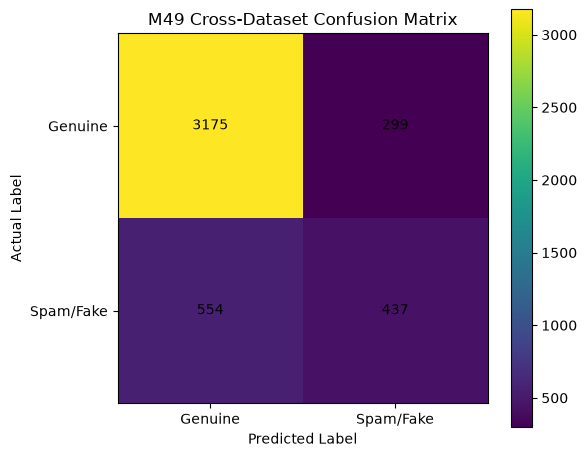

In [26]:
plt.figure(figsize=(6, 5))

plt.imshow(cm)

plt.title("M49 Cross-Dataset Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.xticks(
    [0, 1],
    ["Genuine", "Spam/Fake"]
)

plt.yticks(
    [0, 1],
    ["Genuine", "Spam/Fake"]
)

for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        plt.text(
            j,
            i,
            cm[i, j],
            ha="center",
            va="center"
        )

plt.colorbar()
plt.tight_layout()
plt.show()

In [27]:
prediction_distribution = pd.Series(
    external_predictions
).value_counts().sort_index()

prediction_distribution.index = [
    "Genuine" if index == 0 else "Spam/Fake"
    for index in prediction_distribution.index
]

print(prediction_distribution)

Genuine      3729
Spam/Fake     736
Name: count, dtype: int64


In [28]:
comparison_df = pd.DataFrame({
    "actual": y_external.values,
    "predicted": external_predictions,
    "fake_probability": external_probabilities
})

comparison_df["actual_label"] = comparison_df["actual"].map({
    0: "Genuine",
    1: "Spam/Fake"
})

comparison_df["predicted_label"] = comparison_df["predicted"].map({
    0: "Genuine",
    1: "Spam/Fake"
})

display(comparison_df.head(20))

,actual,predicted,fake_probability,actual_label,predicted_label
0,0,0,0.303333,Genuine,Genuine
1,0,0,0.133333,Genuine,Genuine
2,0,0,0.073333,Genuine,Genuine
3,0,0,0.000000,Genuine,Genuine
4,0,1,0.830000,Genuine,Spam/Fake
5,0,0,0.063333,Genuine,Genuine
6,0,0,0.003333,Genuine,Genuine
7,0,0,0.070000,Genuine,Genuine
8,0,0,0.030000,Genuine,Genuine
9,0,0,0.000000,Genuine,Genuine


In [29]:
misclassified = comparison_df[
    comparison_df["actual"] != comparison_df["predicted"]
].copy()

print("Total misclassified samples:", len(misclassified))

print(
    "Misclassification rate:",
    f"{len(misclassified) / len(comparison_df) * 100:.2f}%"
)

display(misclassified.head(20))

Total misclassified samples: 853
Misclassification rate: 19.10%


,actual,predicted,fake_probability,actual_label,predicted_label
4,0,1,0.830000,Genuine,Spam/Fake
14,0,1,0.656667,Genuine,Spam/Fake
33,0,1,0.983333,Genuine,Spam/Fake
37,0,1,0.526667,Genuine,Spam/Fake
46,0,1,0.550000,Genuine,Spam/Fake
86,0,1,0.630000,Genuine,Spam/Fake
113,0,1,0.816667,Genuine,Spam/Fake
121,0,1,0.763333,Genuine,Spam/Fake
131,0,1,0.870000,Genuine,Spam/Fake
134,0,1,0.776667,Genuine,Spam/Fake


In [30]:
result_df = external_df.copy()

result_df["predicted"] = external_predictions
result_df["fake_probability"] = external_probabilities

result_df["actual_label"] = result_df["label"].map({
    0: "Genuine",
    1: "Spam/Fake"
})

result_df["predicted_label"] = result_df["predicted"].map({
    0: "Genuine",
    1: "Spam/Fake"
})

result_df["correct"] = (
    result_df["label"] ==
    result_df["predicted"]
)

print("Result dataset shape:")
print(result_df.shape)

display(
    result_df[
        [
            "screen_name",
            "followers_count",
            "friends_count",
            "statuses_count",
            "label",
            "predicted",
            "fake_probability",
            "correct"
        ]
    ].head(20)
)

Result dataset shape:
(4465, 48)


,screen_name,followers_count,friends_count,statuses_count,label,predicted,fake_probability,correct
0,0918Bask,208,332,2177,0,0,0.303333,True
1,1120Roll,330,485,2660,0,0,0.133333,True
2,14KBBrown,166,177,1254,0,0,0.073333,True
3,wadespeters,2248,981,202968,0,0,0.000000,True
4,191a5bd05da04dc,21,79,82,0,1,0.830000,False
5,19_Joanne_87,641,1066,12915,0,0,0.063333,True
6,1Dniallprincess,1042,2000,13676,0,0,0.003333,True
7,1GisellePizarro,561,118,61294,0,0,0.070000,True
8,1Nicoleromany,337,256,4854,0,0,0.030000,True
9,1_DErika,421,338,2408,0,0,0.000000,True


In [31]:
misclassified_profiles = result_df[
    result_df["correct"] == False
].copy()

columns_to_show = [
    "screen_name",
    "followers_count",
    "friends_count",
    "statuses_count",
    "description",
    "label",
    "predicted",
    "fake_probability"
]

display(
    misclassified_profiles[
        columns_to_show
    ].head(30)
)

,screen_name,followers_count,friends_count,statuses_count,description,label,predicted,fake_probability
4,191a5bd05da04dc,21,79,82,Cosmetologist,0,1,0.830000
14,510Daniel,16,74,88,Oakland born and raised!! SJSU Graduate #Servi...,0,1,0.656667
33,ARHG66,10,91,54,NaN,0,1,0.983333
37,A_AlRuwaieh,25,28,416,A minimalist realist who likes tea.,0,1,0.526667
46,AboutFactsNet,28,32,3114,I am the webmaster of About Facts Internet mag...,0,1,0.550000
86,Almina_AB,53,272,911,NaN,0,1,0.630000
113,AndyChatlani,23,102,157,NaN,0,1,0.816667
121,Anis_SGL,14,38,1271,NaN,0,1,0.763333
131,Araceli94999080,34,351,811,NaN,0,1,0.870000
134,ArianaReweti,72,460,133,NaN,0,1,0.776667


In [32]:
metrics_df = pd.DataFrame({
    "dataset": ["Cresci2017_External"],
    "samples": [len(y_external)],
    "genuine_samples": [(y_external == 0).sum()],
    "spam_samples": [(y_external == 1).sum()],
    "accuracy": [accuracy],
    "precision": [precision],
    "recall": [recall],
    "f1": [f1],
    "roc_auc": [roc_auc]
})

METRICS_PATH = PROCESSED_DIR / "cross_dataset_results.csv"

metrics_df.to_csv(
    METRICS_PATH,
    index=False
)

print("✓ M49 metrics saved to:")
print(METRICS_PATH)

✓ M49 metrics saved to:
c:\Users\Acer\Documents\AuthentiScore\data\processed\cross_dataset_results.csv


In [33]:
cm_df = pd.DataFrame(
    cm,
    index=["Actual_Genuine", "Actual_Spam"],
    columns=["Predicted_Genuine", "Predicted_Spam"]
)

CM_PATH = PROCESSED_DIR / "cross_dataset_confusion_matrix.csv"

cm_df.to_csv(
    CM_PATH
)

print("✓ Confusion matrix saved to:")
print(CM_PATH)

✓ Confusion matrix saved to:
c:\Users\Acer\Documents\AuthentiScore\data\processed\cross_dataset_confusion_matrix.csv


In [34]:
PREDICTIONS_PATH = (
    PROCESSED_DIR /
    "cross_dataset_predictions.csv"
)

result_df.to_csv(
    PREDICTIONS_PATH,
    index=False
)

print("✓ Detailed predictions saved to:")
print(PREDICTIONS_PATH)

✓ Detailed predictions saved to:
c:\Users\Acer\Documents\AuthentiScore\data\processed\cross_dataset_predictions.csv


In [35]:
print("=" * 60)
print("M49 — CROSS-DATASET TESTING COMPLETE")
print("=" * 60)

print(f"External samples : {len(y_external)}")
print(f"Genuine samples  : {(y_external == 0).sum()}")
print(f"Spam samples     : {(y_external == 1).sum()}")

print("\nPerformance:")
print(f"Accuracy  : {accuracy * 100:.2f}%")
print(f"Precision : {precision * 100:.2f}%")
print(f"Recall    : {recall * 100:.2f}%")
print(f"F1 Score  : {f1 * 100:.2f}%")
print(f"ROC-AUC   : {roc_auc * 100:.2f}%")

print("\nOutput files:")
print(f"1. {METRICS_PATH}")
print(f"2. {CM_PATH}")
print(f"3. {PREDICTIONS_PATH}")

print("\nM49 completed.")

M49 — CROSS-DATASET TESTING COMPLETE
External samples : 4465
Genuine samples  : 3474
Spam samples     : 991

Performance:
Accuracy  : 80.90%
Precision : 59.38%
Recall    : 44.10%
F1 Score  : 50.61%
ROC-AUC   : 62.60%

Output files:
1. c:\Users\Acer\Documents\AuthentiScore\data\processed\cross_dataset_results.csv
2. c:\Users\Acer\Documents\AuthentiScore\data\processed\cross_dataset_confusion_matrix.csv
3. c:\Users\Acer\Documents\AuthentiScore\data\processed\cross_dataset_predictions.csv

M49 completed.
